# Closed-Loop Framework — Ground-Truth Simulation (companion notebook)

Companion to the manuscript on a closed-loop framework for **diagnostic appraisal** of knowledge-based causal models using process mining and human–AI governance.

**Read this first.** This is a *known-answer (positive-control) test*. The use case (PPI vs H2B, CKD, CVAE, death) was chosen because its results were already published by the authors; calibration, artefacts and gate rules were written knowing the answer, by people who are not independent of it. The simulation tests whether the machinery can recover known structure and what it does when the rules are not written for the situation. It does **not** test LLM proposals, human adjudication, or performance on a new question, and structural metrics measure classification of simulator transitions, **not** recovery of a causal DAG.

States: **S0** index/on-drug → **S1** CKD → **S2** CVAE → **S3** Death. Designed artefacts (recorded, not causal): `S2→S0` (drug-feedback decoy) and `S2→S1` (reverse coding shift).

## 0. Setup

Runs locally from the repository root (`pip install -r requirements.txt`). The repository is private; to use Colab, clone it with a personal access token first.

In [1]:
import os, sys
try:
    import closed_loop_sim
except ModuleNotFoundError:           # running from notebooks/ inside the repo
    sys.path.insert(0, os.path.abspath(".."))
    import closed_loop_sim
print("closed_loop_sim imported from", os.path.dirname(closed_loop_sim.__file__))

closed_loop_sim imported from /Users/sabt/Downloads/closedloop-companion-new/repo/closed_loop_sim


## 1. The latent truth (DGP)

Each patient walks a continuous-time multi-state model with Weibull proportional-hazards intensities. Exposure (PPI=1, H2B=0) is assigned by a confounded propensity model. The exposure effect is positive on `S0→S1` and **exactly zero on `S1→S2`**.

In [2]:
from closed_loop_sim.config import base_cell
from closed_loop_sim.dgp import simulate_population

cfg = base_cell()
pop = simulate_population(2000, cfg, seed=1)
print("PPI prevalence:", round(pop.E.mean(), 3))
print("example trajectory:", pop.histories[0])
print("beta_E  S0->S1 =", cfg.dgp.transitions["S0->S1"].beta_E, "|  S1->S2 =", cfg.dgp.transitions["S1->S2"].beta_E)

PPI prevalence: 0.66
example trajectory: [('S0', 0.0), ('S1', 2.305104377112707)]
beta_E  S0->S1 = 0.25 |  S1->S2 = 0.0


## 2. The oracle

Because we own the DGP, the simulator is the oracle. For the **primary estimand** — the standardised 10-year CKD risk difference with death (and a CVAE occurring first) as competing events — it is obtained by counterfactual simulation with common random numbers across the two exposure worlds. The archived study uses 1,000,000 patients; the cell below uses the cached value if present, else a smaller run.

In [3]:
from closed_loop_sim.truth import TRUE_EDGES, TRAP_EDGES, ckd_truth, cached_oracle
from pathlib import Path
print("true transitions:", sorted(TRUE_EDGES))
print("designed artefacts (traps):", sorted(TRAP_EDGES))

cache = Path("../results/oracle_ckd.json")
oracle = cached_oracle(cfg, cache, n=1_000_000) if cache.exists() else ckd_truth(cfg, 50_000, 999, cfg.dgp.t_max)
print(f"oracle risk difference = {oracle['risk_difference']:.4f} (SE {oracle['risk_difference_se']:.4f}, n = {oracle['n']:,}); "
      f"risk ratio = {oracle['risk_ratio']:.3f}")

true transitions: [('S0', 'S1'), ('S0', 'S2'), ('S0', 'S3'), ('S1', 'S2'), ('S1', 'S3'), ('S2', 'S3')]
designed artefacts (traps): [('S2', 'S0'), ('S2', 'S1')]
oracle risk difference = 0.0461 (SE 0.0002, n = 1,000,000); risk ratio = 1.214


## 3. The observation process and the artefacts

We record the latent process through visits. PPI users are monitored more (`kappa`), so disease is detected sooner **and more often**. Follow-up ends at death (or loss to follow-up, if enabled); the designed artefacts are injected after a recorded CVAE.

In [4]:
from closed_loop_sim.eventlog import build_event_log_data

data = build_event_log_data(6000, cfg, seed=1)
log = data.log
display(log.head(8))
acts = set(log["activity"].unique())
print("artefacts present:", "MedicationChange" in acts, "CKD_recode" in acts)
ckd = log[log.activity == "CKD_recorded"]
print("median CKD recorded time  PPI:", round(ckd[ckd.group=="PPI"].time.median(), 2),
      " H2B:", round(ckd[ckd.group=="H2B"].time.median(), 2), "(PPI earlier = surveillance)")

,case,activity,time,group
0,0,IndexDrug,0.000000,PPI
1,0,CKD_recorded,4.976169,PPI
2,1,IndexDrug,0.000000,H2B
3,2,IndexDrug,0.000000,PPI
4,2,CKD_recorded,7.749292,PPI
5,3,IndexDrug,0.000000,PPI
6,4,IndexDrug,0.000000,PPI
7,5,IndexDrug,0.000000,PPI


artefacts present: True True
median CKD recorded time  PPI: 5.14  H2B: 5.43 (PPI earlier = surveillance)


## 4. Discovery: the process map

The recorded log becomes a directly-follows graph (pm4py), mapped to the state nodes. The two designed artefacts appear alongside the true edges.

S2->S0  risk=0.28  median=0.4y  [TRAP]
S2->S3  risk=0.28  median=1.2y  [true/initial]
S0->S1  risk=0.23  median=5.1y  [true/initial]
S1->S3  risk=0.21  median=2.1y  [true/initial]
S2->S1  risk=0.17  median=0.3y  [TRAP]
S1->S2  risk=0.15  median=2.2y  [true/initial]
S0->S3  risk=0.05  median=4.7y  [true/initial]
S0->S2  risk=0.04  median=4.7y  [true/initial]
wrote /Users/sabt/Downloads/closedloop-companion-new/repo/results/process_map.png


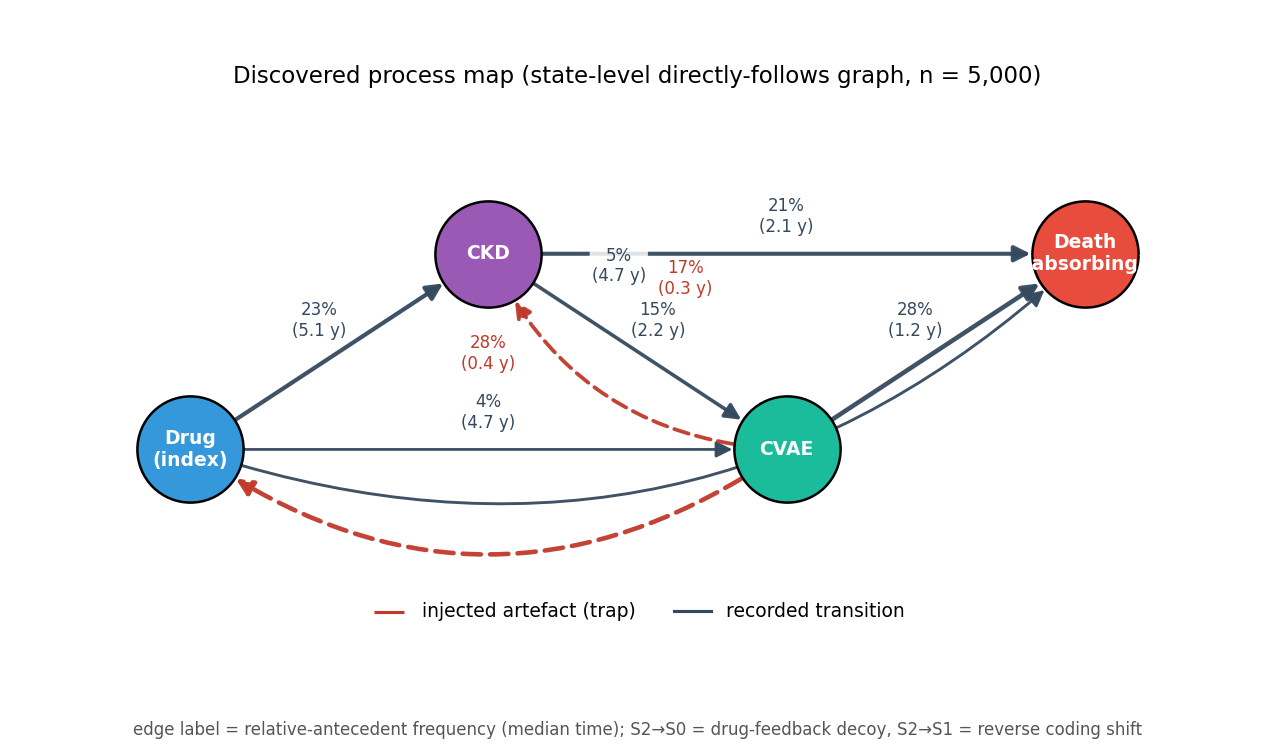

In [5]:
from closed_loop_sim.discovery import discover
from closed_loop_sim.visualize import process_map
from IPython.display import Image

disc = discover(log, data.visit_counts)
for (a, b), e in sorted(disc.state_edges.items(), key=lambda x: -x[1].risk):
    tag = "TRAP" if (a, b) in TRAP_EDGES else "true/initial"
    print(f"{a}->{b}  risk={e.risk:.2f}  median={e.median_time:.1f}y  [{tag}]")
process_map(disc)
Image("../results/process_map.png")

## 5. Refinement arms

Refinement starts from the initial knowledge graph `{S0→S1, S0→S2, S1→S2}`.

| Arm | Gate |
|---|---|
| A | none: accepts every frequent proposal and every removal proposal |
| B | **two prespecified rules** (backward edge; administrative activity), written knowing the two designed artefacts |
| B_unk | B plus a rule for nodes outside the Phase-1 ordering |
| B_defer | three-way gate: backward and unrecognised candidates are **deferred to the expert** |
| C | oracle |
| Initial | no refinement |
| PC_Temporal | forward-order filter (a generic temporal baseline — **not** PC or GES) |

A            traps accepted: [('S2', 'S0'), ('S2', 'S1')] | Death node: True | deferred: 0
B            traps accepted: [] | Death node: True | deferred: 0
B_unk        traps accepted: [] | Death node: True | deferred: 0
B_defer      traps accepted: [] | Death node: True | deferred: 1
C            traps accepted: [] | Death node: True | deferred: 0
Initial      traps accepted: [] | Death node: False | deferred: 0
PC_Temporal  traps accepted: [] | Death node: True | deferred: 0
wrote /Users/sabt/Downloads/closedloop-companion-new/repo/results/dag_refinement.png


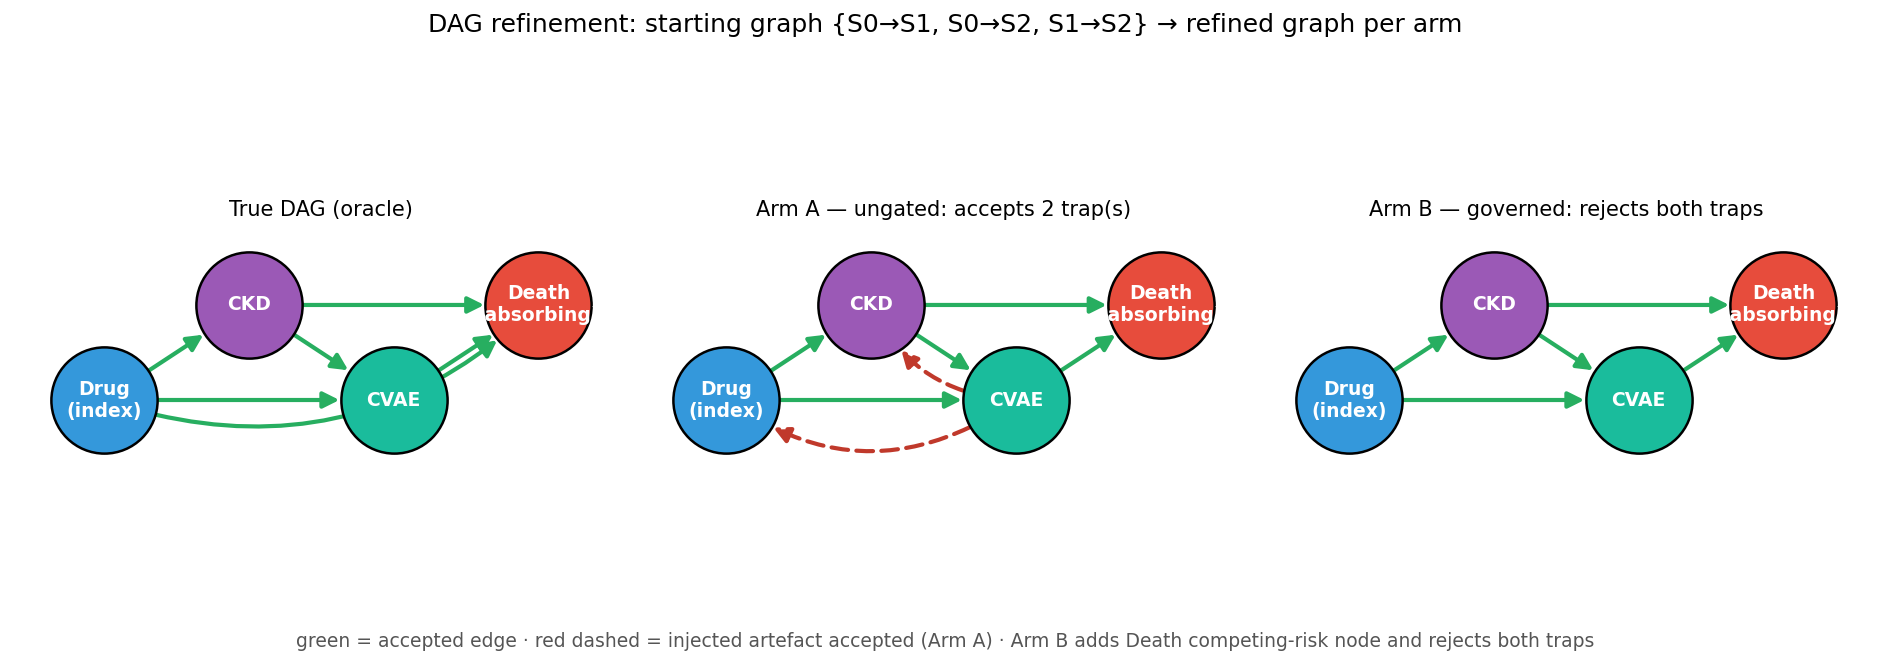

In [6]:
from closed_loop_sim.refinement import ARMS
from closed_loop_sim.visualize import dag_refinement

for arm, run in ARMS.items():
    res = run(disc)
    deferred = sum(1 for _, d in res.decisions if getattr(d, "deferred", False))
    print(f"{arm:12} traps accepted: {sorted(set(res.edges) & TRAP_EDGES)} | Death node: {'S3' in res.nodes} | deferred: {deferred}")
dag_refinement({arm: set(ARMS[arm](disc).edges) for arm in "ABC"})
Image("../results/dag_refinement.png")

## 6. Structural classification metrics

Arm B's perfect precision and 0% trap acceptance are **guaranteed by construction** (its rules were written for these artefacts): a positive control, not evidence of generalisation. A simple forward-order filter achieves the same here. Recall is 0.83 because the rare `S0→S3` edge (recorded risk ≈ 0.05) is below the 10% support threshold — a limitation of the threshold, not of sample size.

In [7]:
from closed_loop_sim.metrics import structural_metrics

for arm in ARMS:
    m = structural_metrics(ARMS[arm](disc))
    print(f"{arm:12} precision={m['precision']:.2f} recall={m['recall']:.2f} F1={m['f1']:.2f} SHD={m['shd']} traps={m['n_traps_accepted']}")

A            precision=0.71 recall=0.83 F1=0.77 SHD=3 traps=2
B            precision=1.00 recall=0.83 F1=0.91 SHD=1 traps=0
B_unk        precision=1.00 recall=0.83 F1=0.91 SHD=1 traps=0
B_defer      precision=1.00 recall=0.83 F1=0.91 SHD=1 traps=0
C            precision=1.00 recall=1.00 F1=1.00 SHD=0 traps=0
Initial      precision=1.00 recall=0.50 F1=0.67 SHD=3 traps=0
PC_Temporal  precision=1.00 recall=0.83 F1=0.91 SHD=1 traps=0


## 7. What happens when the rules were not written for the situation

Add a **held-out artefact** (`Lab_Reassay`, recorded after a CVAE with probability 0.4). It maps to a node outside the Phase-1 ordering and outside the gate's vocabulary.

In [8]:
cfg_ho = base_cell(); cfg_ho.obs.p_held_out = 0.4
data_ho = build_event_log_data(6000, cfg_ho, seed=3)
disc_ho = discover(data_ho.log, data_ho.visit_counts)
for arm in ["A", "B", "B_unk", "B_defer"]:
    r = ARMS[arm](disc_ho); m = structural_metrics(r)
    print(f"{arm:8} precision={m['precision']:.2f} accepts held-out artefact={m['accepted_held_out']} deferred={m['n_deferred']}")

A        precision=0.56 accepts held-out artefact=True deferred=0
B        precision=0.71 accepts held-out artefact=True deferred=0
B_unk    precision=1.00 accepts held-out artefact=False deferred=0
B_defer  precision=1.00 accepts held-out artefact=False deferred=3


The two-rule gate accepts the held-out artefact; one extra rule fixes **this** case (it does not show the next unseen artefact would be caught); the three-way gate turns the failure into expert workload. See the manuscript for true feedback, edge removal, a negative control, a latent common cause and loss to follow-up (`python -m closed_loop_sim.sweeps`).

## 8. Primary estimand and the surveillance-bias story

Per arm, the refined graph determines whether the outcome is contaminated by recoded events and whether death is modelled as a competing event. **Identification**: the back-door criterion is evaluated for the *recorded* outcome; the effect on the *latent* onset is **not identified from recorded data in any arm** (detection depends on exposure).

**Caution:** the cell below uses a *single* dataset, which is noisy (the standard deviation of the risk difference is about 0.014 at n = 5,000), so its ratio to the oracle can differ a lot from the archived 500-replication figure (about 1.2). Use the archived summary at the end of the notebook for conclusions.

In [9]:
from closed_loop_sim.estimation import estimate, estimate_arm
from closed_loop_sim.causal import arm_identification

e = estimate(data, cfg.dgp.t_max)
lat = e["latent_ipw_cif"]["risk_difference"]
print(f"oracle RD {oracle['risk_difference']:.4f} | latent-process estimate {lat:.4f}")
for arm in ["A", "B", "Initial"]:
    est = estimate_arm(data, cfg.dgp.t_max, ARMS[arm](disc))
    ident = arm_identification(ARMS[arm](disc))
    print(f"{arm:8} recorded RD = {est['ipw_cif']['risk_difference']:.4f}  (x{est['ipw_cif']['risk_difference']/oracle['risk_difference']:.2f} oracle) | "
          f"state graph acyclic={ident['state_graph_acyclic']} contaminated={ident['outcome_contaminated']} "
          f"death modelled={ident['has_death_node']} latent effect identified={ident['latent_effect_identified']}")
print("\nCox log-HR (secondary; truth 0.25):")
for k in ["s0s1_latent", "s0s1_naive", "s0s1_adjusted"]:
    print(f"  {k:14} beta_E = {e[k]['beta_E']:.3f}")

oracle RD 0.0461 | latent-process estimate 0.0584
A        recorded RD = 0.0733  (x1.59 oracle) | state graph acyclic=False contaminated=True death modelled=True latent effect identified=False
B        recorded RD = 0.0693  (x1.50 oracle) | state graph acyclic=True contaminated=False death modelled=True latent effect identified=False
Initial  recorded RD = 0.0712  (x1.55 oracle) | state graph acyclic=True contaminated=False death modelled=False latent effect identified=False

Cox log-HR (secondary; truth 0.25):
  s0s1_latent    beta_E = 0.292
  s0s1_naive     beta_E = 0.385
  s0s1_adjusted  beta_E = 0.703


**Where the bias comes from.** In the simulator we can measure the *sensitivity of CKD detection* by exposure group. A quantitative bias analysis with the true sensitivities shows the mechanism; with assumed values it is only a sensitivity analysis (ratios above 1/Se₀ are infeasible and are returned as NaN).

In [10]:
d, q = e["detection_oracle"], e["qba"]
print(f"detection sensitivity  PPI={d['se1']:.3f}  H2B={d['se0']:.3f}  ratio={d['se_ratio']:.3f}")
print(f"recorded RD={q['recorded_rd']:.4f} -> adjusted with true sensitivities={q['oracle_adjusted_rd']:.4f} (oracle {oracle['risk_difference']:.4f})")
print("adjusted RD for assumed ratios (Se0 = 0.80):", {k: round(v, 4) for k, v in q["adjusted_rd"].items()})
print("ratio that would null the association:", round(q["ratio_that_nulls"], 2), "| feasible:", q["nulling_ratio_feasible"])

detection sensitivity  PPI=0.939  H2B=0.863  ratio=1.088
recorded RD=0.0693 -> adjusted with true sensitivities=0.0572 (oracle 0.0461)
adjusted RD for assumed ratios (Se0 = 0.80): {'1.00': 0.0866, '1.10': 0.0587, '1.20': 0.0354, '1.25': 0.0252}
ratio that would null the association: 1.39 | feasible: False


## 9. The full study

Aggregate over replications (use a small `M` here; `python -m closed_loop_sim.run_study 500` runs the archived study with bootstrap intervals and the 1,000,000-patient oracle).

accepts >=1 designed artefact:  A = 1.0  B = 0.0
latent-process RD bias: 0.0025
A        recorded RD bias = 0.0176 (MCSE 0.0034)
B        recorded RD bias = 0.0134 (MCSE 0.0035)
Initial  recorded RD bias = 0.0147 (MCSE 0.0035)


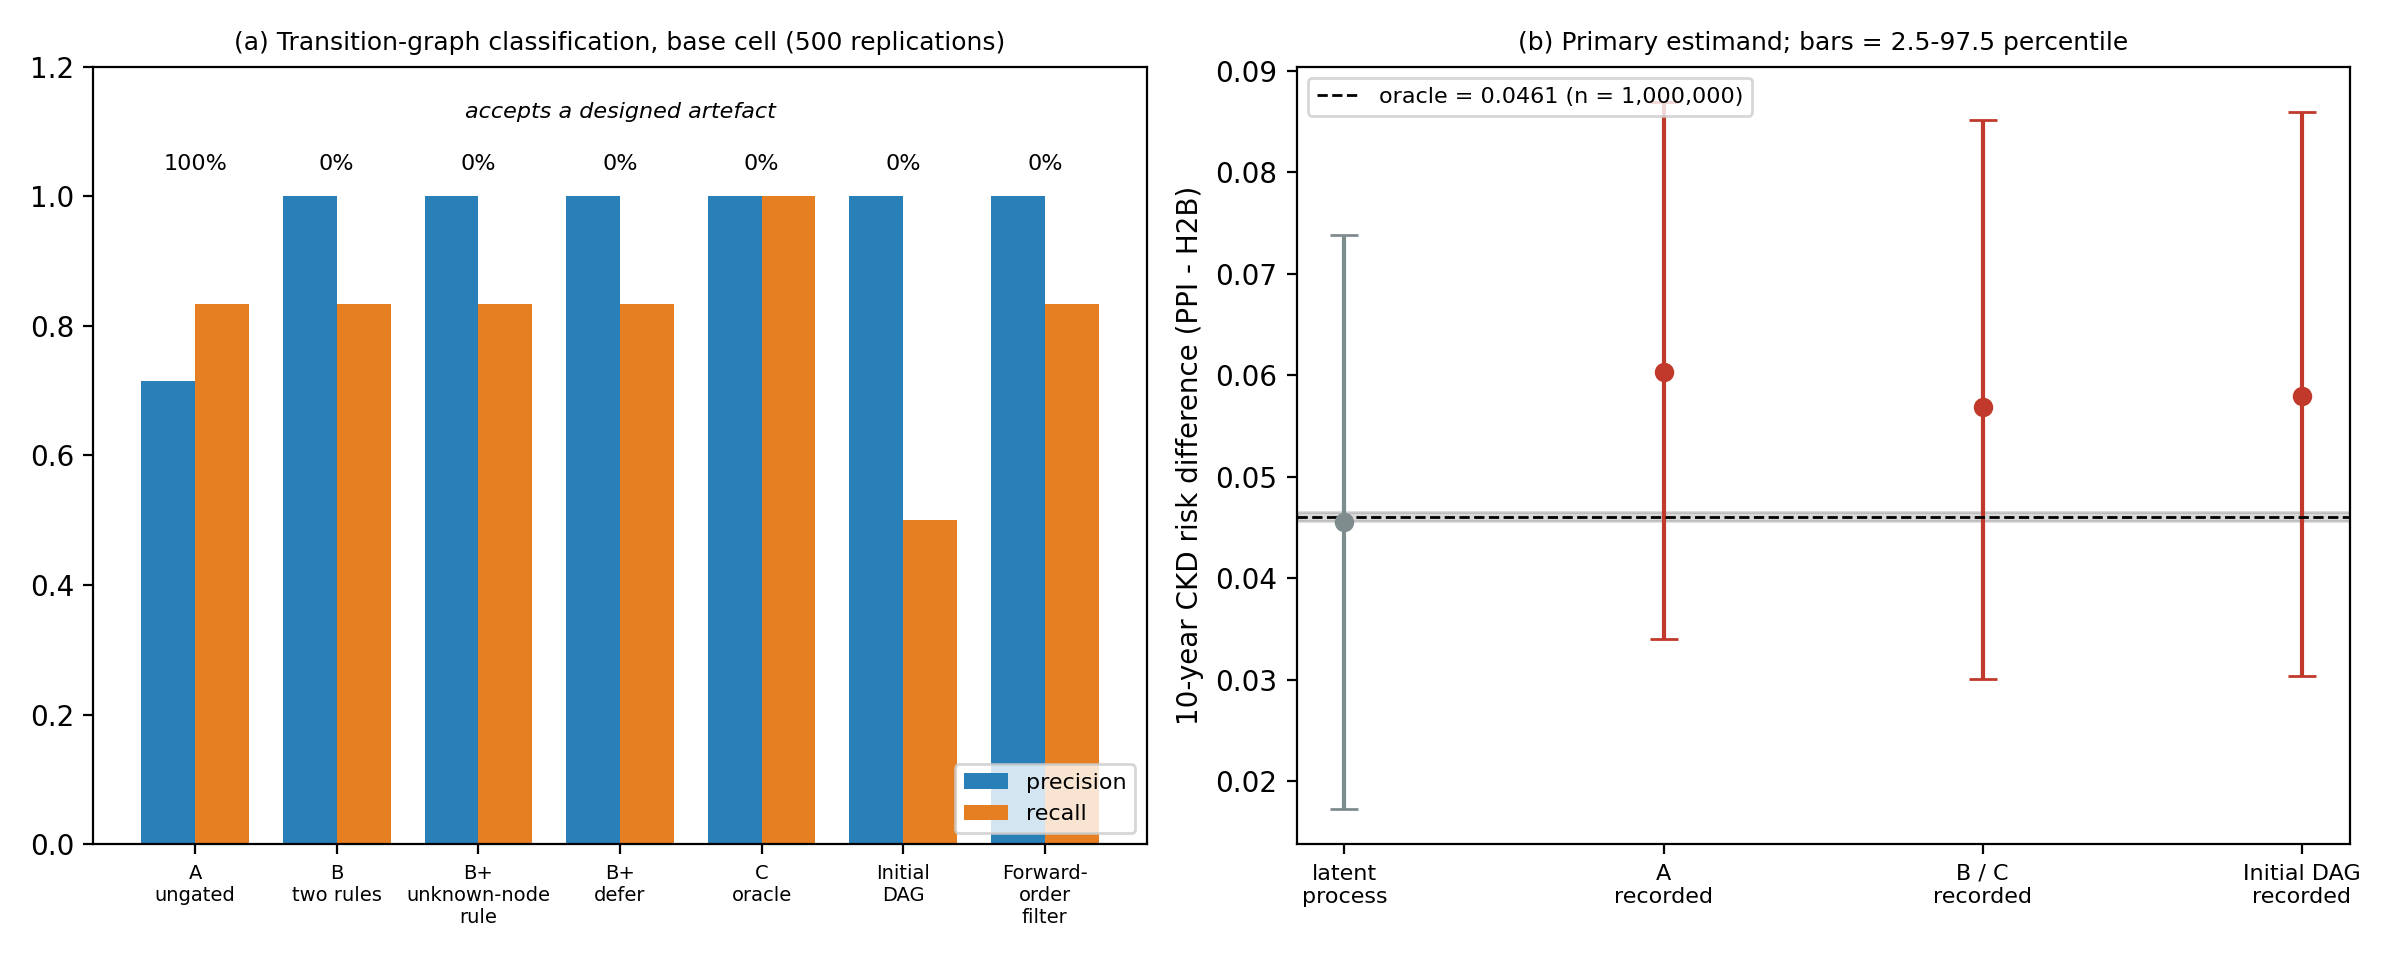

In [11]:
from closed_loop_sim.experiment import run_cell

res = run_cell(cfg, M=20, with_estimation=True, oracle=oracle, arms=["A", "B", "Initial"])
print("accepts >=1 designed artefact:  A =", res["structural"]["A"]["accept_any_trap_rate"], " B =", res["structural"]["B"]["accept_any_trap_rate"])
est = res["estimation"]
print("latent-process RD bias:", round(est["latent_primary"]["risk_difference"]["bias"], 4))
for a in ["A", "B", "Initial"]:
    b = est["by_arm"][a]["risk_difference"]
    print(f"{a:8} recorded RD bias = {b['bias']:.4f} (MCSE {b['mcse']:.4f})")
Image("../results/figure_simulation.png")   # pre-rendered from the archived M=500 run

## Summary of the archived study (read from `results/`)

In [12]:
import json, pandas as pd
r = json.load(open("../results/base_cell_results.json")); S = r["cell"]["structural"]; E = r["cell"]["estimation"]
t = E["truth_ckd_cif"]["risk_difference"]; B = E["by_arm"]["B"]; A = E["by_arm"]["A"]; D = E["detection_oracle_mean"]
names = {"A":"A ungated","B":"B two rules","B_unk":"B + unknown-node rule","B_defer":"B + defer","C":"C oracle","Initial":"Initial DAG","PC_Temporal":"Forward-order filter"}
display(pd.DataFrame({names[a]: {"precision": round(S[a]["precision_mean"],2), "recall": round(S[a]["recall_mean"],2),
                                  "accepts a designed artefact": f"{S[a]['accept_any_trap_rate']:.0%}"} for a in names}).T)
print(f"M = {r['meta']['M']} replications. Oracle RD = {t:.4f}; recorded RD (governed) = {B['risk_difference']['mean']:.4f} "
      f"(x{B['risk_difference']['mean']/t:.2f}); 95% interval coverage = {B['rd_ci_coverage']['coverage']:.2f}")
print(f"Ungated minus governed bias = {A['risk_difference']['bias']-B['risk_difference']['bias']:.4f}; detection sensitivity PPI {D['se1']:.2f} vs H2B {D['se0']:.2f}")

,precision,recall,accepts a designed artefact
A ungated,0.71,0.83,100%
B two rules,1.0,0.83,0%
B + unknown-node rule,1.0,0.83,0%
B + defer,1.0,0.83,0%
C oracle,1.0,1.0,0%
Initial DAG,1.0,0.5,0%
Forward-order filter,1.0,0.83,0%


M = 500 replications. Oracle RD = 0.0461; recorded RD (governed) = 0.0569 (x1.23); 95% interval coverage = 0.87
Ungated minus governed bias = 0.0034; detection sensitivity PPI 0.94 vs H2B 0.88


## What this does and does not show

* The pipeline reproduced most of the known structure (five of six transitions and the competing-risk node); the two-rule gate rejects the two designed artefacts — **by construction**.
* The gate fails on artefacts and situations its rules were not written for; a forward-order filter ties it in the base cell.
* On recorded data the primary risk difference is inflated about 1.2-fold, almost entirely by **differential detection** of CKD. Graph refinement prevents a *small additional* bias (contamination by recoded events, an unmodelled competing event); it does **not** improve accuracy beyond the best available graph, and nothing here identifies the latent effect from recorded data.
* No human or LLM adjudication is simulated. The use case was chosen for its known answer, so this is a positive-control test.

See `docs/METHODS_SPEC.md` for the original spec (partly superseded; the manuscript appendix and `README.md` are authoritative for this revision). The R port in `R/` is **legacy** (original design) and was not updated.